In [1]:
# Import packages
import pandas as pd
import csv
import os
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load the dataset
df_path = ('bank+marketing/bank-additional/bank-additional-full.csv')
bank_df = pd.read_csv(df_path, sep = ';')
pd.set_option("display.max_columns", None)
display(bank_df.head(10))

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,198,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,139,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,217,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,380,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,25,services,single,high.school,no,yes,no,telephone,may,mon,50,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


- **pdays**: how many days since the last contact (999 means no call before)
- **previous**: how many calls they gave the person before that campaign
- **emp.var.rate**: employment variation rate (shows if employment increases or decreases)
- **cons.price.idx**: consumer price index (inflation, how expensive the lifestyle is)
- **cons.conf.idx**: consumer confidence index (how positive people feel about the current economy)
- **euribor3m**: 3 months Eurobirom rate
- **nr.employed**: total number of employments (3month period, in thousands)

In [3]:
# 3. Number of samples and attributes
print(f"Samples: {bank_df.shape[0]}")
print(f"Attributes: {bank_df.shape[1]-1}") # -1 to not count the target column

Samples: 41188
Attributes: 20


In [4]:
bank_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [5]:
bank_df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [6]:
print(f"Duplicates: {bank_df.duplicated().sum()} row/rows")

Duplicates: 12 row/rows


In [7]:
bank_df['y'].value_counts(normalize = True)

y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64

Text(0.5, 0, 'Subscription of term deposit')

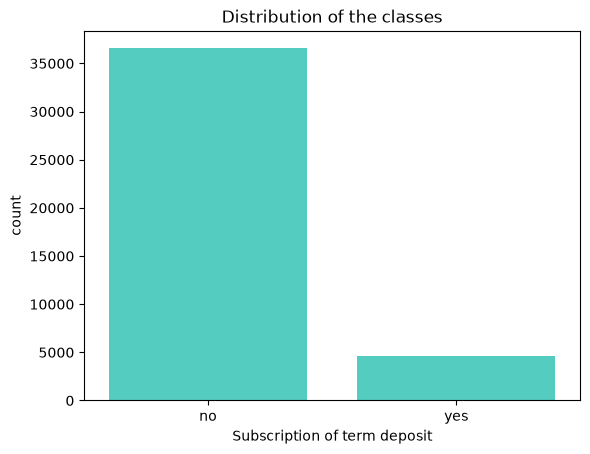

In [8]:
y_barchart = sns.countplot(data = bank_df, x = 'y', stat = 'count', color = 'turquoise')
y_barchart.set_title("Distribution of the classes")
y_barchart.set_xlabel("Subscription of term deposit")

Text(0.5, 0, 'duration (s)')

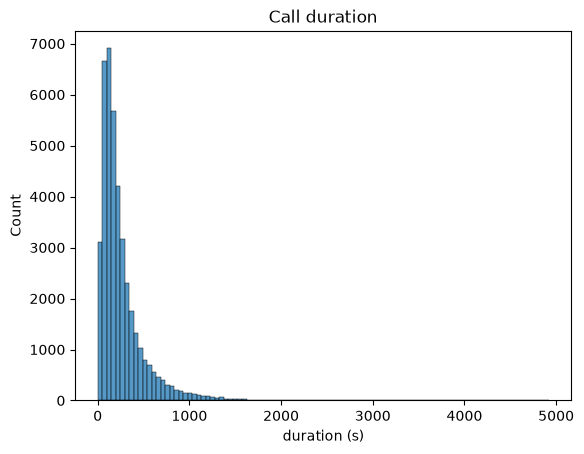

In [9]:
duration_ax = sns.histplot(bank_df, x = 'duration', stat = 'count', bins = 100)
duration_ax.set_title("Call duration")
duration_ax.set_xlabel("duration (s)")

Text(0.5, 0, 'age (years)')

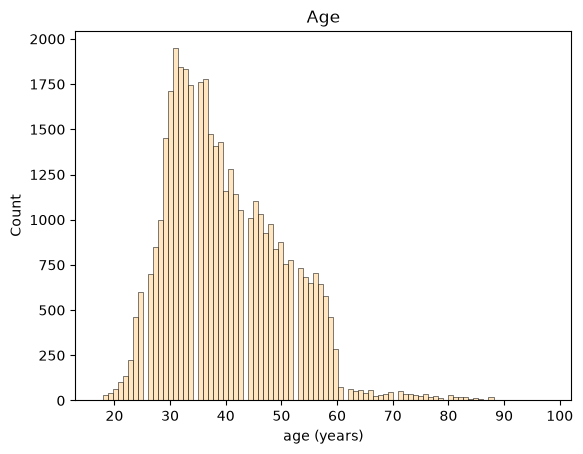

In [10]:
age_ax = sns.histplot(bank_df, x = 'age', stat = 'count', bins = 90, color = "navajowhite")
age_ax.set_title("Age")
age_ax.set_xlabel("age (years)")

Text(0.5, 1.0, 'Marital situation')

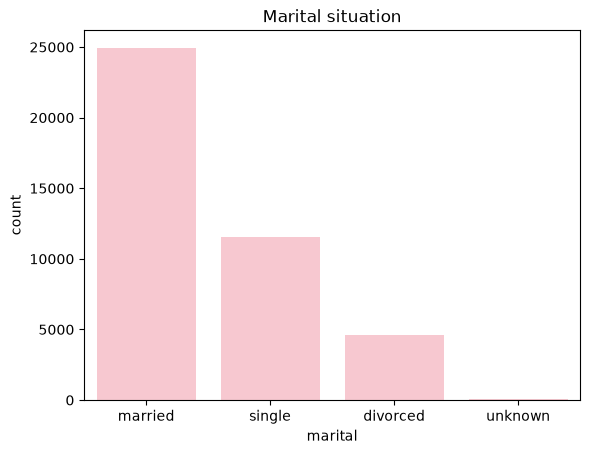

In [11]:
marital_barchart = sns.countplot(bank_df, x = 'marital', stat = 'count', color = 'pink')
marital_barchart.set_title("Marital situation")

Text(0.5, 1.0, 'Education')

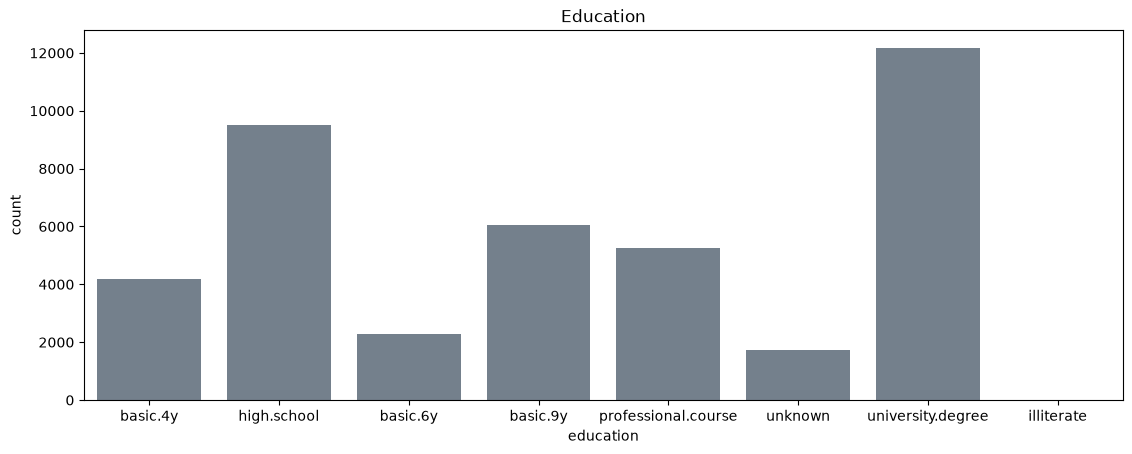

In [12]:
plt.figure(figsize = (13.4, 4.8))
education_barchart = sns.countplot(bank_df, x = 'education', stat = 'count', color = 'slategrey')
education_barchart.set_title("Education")

Text(0.5, 1.0, 'Job')

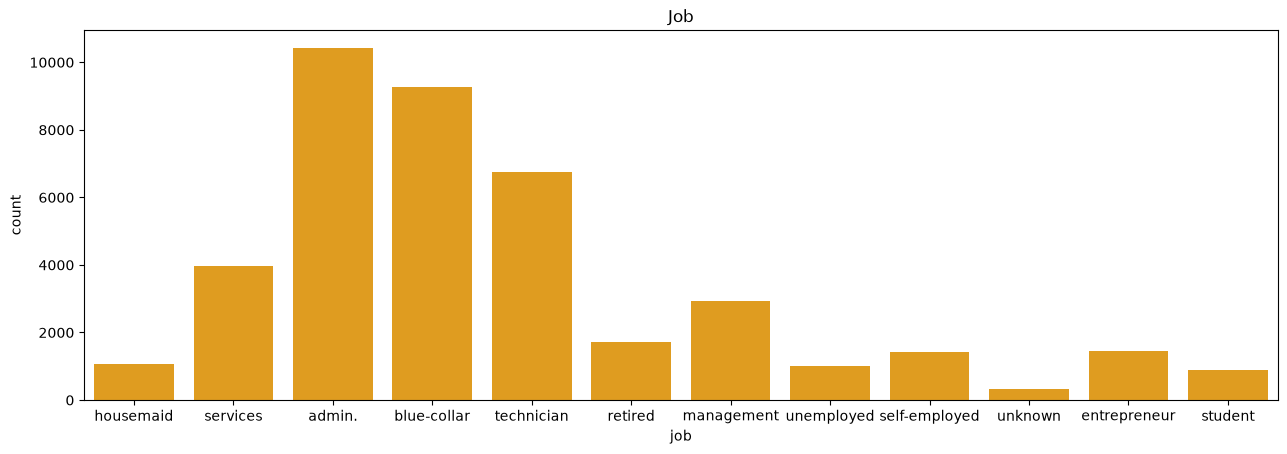

In [13]:
plt.figure(figsize = (15.4, 4.8))
job_barchart = sns.countplot(bank_df, x = 'job', stat = 'count', color = 'orange')
job_barchart.set_title("Job")

In [14]:
bank_df.dtypes

age                 int64
job                   str
marital               str
education             str
default               str
housing               str
loan                  str
contact               str
month                 str
day_of_week           str
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome              str
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                     str
dtype: object

In [15]:
bank_df['default'].value_counts(dropna = False)

default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

In [16]:
bank_df['marital'].value_counts(dropna = False)

marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64

In [17]:
bank_df['contact'].value_counts(dropna = False)

contact
cellular     26144
telephone    15044
Name: count, dtype: int64

In [18]:
bank_df['month'].value_counts(dropna = False)

month
may    13769
jul     7174
aug     6178
jun     5318
nov     4101
apr     2632
oct      718
sep      570
mar      546
dec      182
Name: count, dtype: int64

In [19]:
bank_df['campaign'].value_counts(dropna = False)

campaign
1     17642
2     10570
3      5341
4      2651
5      1599
6       979
7       629
8       400
9       283
10      225
11      177
12      125
13       92
14       69
17       58
16       51
15       51
18       33
20       30
19       26
21       24
22       17
23       16
24       15
27       11
29       10
25        8
28        8
26        8
31        7
30        7
35        5
32        4
33        4
34        3
42        2
40        2
43        2
56        1
39        1
41        1
37        1
Name: count, dtype: int64

In [20]:
bank_df['contact'].value_counts(dropna = False)

contact
cellular     26144
telephone    15044
Name: count, dtype: int64